# Applications III: Optics and Waves

- [A3.1 Blackbody radiation: Wien's law and the colour of the Sun](#blackbody) - *root finding, quadrature (Ch. 2, 3, 4)*
- [A3.2 Fraunhofer diffraction with the FFT](#fraunhofer) - *FFT (Ch. 8)*
- [A3.3 Fresnel diffraction and the Cornu spiral](#fresnel) - *quadrature (Ch. 4)*
- [A3.4 Thin films and Bragg mirrors: the transfer-matrix method](#tmm) - *matrices (Ch. 6)*
- [A3.5 Bending light: ray tracing through a graded-index medium](#rays) - *ODEs (Ch. 5)*
- [Projects](#projects)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.integrate import quad, solve_ivp
from scipy.special import j1, fresnel

h, c, kB = 6.62607015e-34, 299792458.0, 1.380649e-23     # exact SI values

# A3.1 Blackbody radiation: Wien's law and the colour of the Sun <a class="anchor" id="blackbody"></a>
Planck's law gives the spectral radiance per unit wavelength

$$B_\lambda(T) = \frac{2hc^2}{\lambda^5}\frac{1}{e^{hc/\lambda k_BT}-1}.$$

**Wien's displacement law.** Setting $dB_\lambda/d\lambda=0$ and writing $x = hc/\lambda k_BT$ gives the transcendental equation

$$5\left(1-e^{-x}\right) = x,$$

whose non-trivial root gives $\lambda_\text{max}T = hc/(k_Bx) = b$, Wien's constant. Notice the rearrangement $x_{n+1}=5(1-e^{-x_n})$ is a perfect candidate for the simple iteration of Chapter 2 (check: $|\varrho'(x)| = 5e^{-x}\approx 0.03$ near the root - very slowly varying!).

In [2]:
x = 5.0
for n in range(6):
    x = 5*(1 - np.exp(-x))
    print(f'iteration {n+1}: x = {x:.12f}')
x_root = brentq(lambda x: 5*(1 - np.exp(-x)) - x, 1, 10)
b = h*c/(kB*x_root)
print(f'\nbrentq: x = {x_root:.12f}  ->  Wien constant b = {b*1e3:.6f} mm K (CODATA 2.897772 mm K)')
print(f'Sun (T = 5772 K) peaks at {b/5772*1e9:.0f} nm;  a human (310 K) at {b/310*1e6:.1f} um')

iteration 1: x = 4.966310265005
iteration 2: x = 4.965155931341
iteration 3: x = 4.965115686436
iteration 4: x = 4.965114282492
iteration 5: x = 4.965114233515
iteration 6: x = 4.965114231806

brentq: x = 4.965114231744  ->  Wien constant b = 2.897772 mm K (CODATA 2.897772 mm K)
Sun (T = 5772 K) peaks at 502 nm;  a human (310 K) at 9.3 um


**What fraction of the Sun's light is visible?** Integrate Planck's law over 380-750 nm and divide by the total, $\sigma T^4/\pi$. In terms of $x$, the fraction emitted between $x_1$ and $x_2$ is $\frac{15}{\pi^4}\int_{x_1}^{x_2}\frac{x^3}{e^x-1}dx$ - a dimensionless integral we can evaluate with `quad`.

incandescent bulb  T =  3000 K: visible fraction = 10.9%
Sun                T =  5772 K: visible fraction = 43.8%
Vega-like star     T = 10000 K: visible fraction = 39.1%


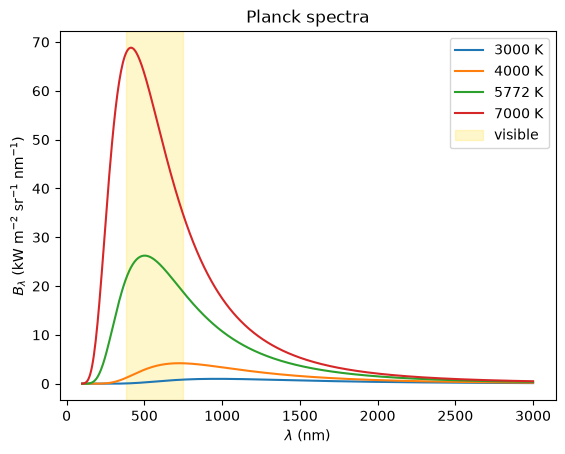

In [3]:
def band_fraction(lam1, lam2, T):
    x1, x2 = h*c/(lam2*kB*T), h*c/(lam1*kB*T)
    return 15/np.pi**4 * quad(lambda x: x**3/np.expm1(x), x1, x2)[0]

for T, name in [(3000, 'incandescent bulb'), (5772, 'Sun'), (10000, 'Vega-like star')]:
    print(f'{name:<18} T = {T:>5} K: visible fraction = {band_fraction(380e-9, 750e-9, T):.1%}')

lam = np.linspace(100e-9, 3000e-9, 500)
for T in [3000, 4000, 5772, 7000]:
    B = 2*h*c**2/lam**5/np.expm1(h*c/(lam*kB*T))
    plt.plot(lam*1e9, B/1e12, label=f'{T} K')
plt.axvspan(380, 750, color='gold', alpha=0.2, label='visible')
plt.xlabel(r'$\lambda$ (nm)'); plt.ylabel(r'$B_\lambda$ (kW m$^{-2}$ sr$^{-1}$ nm$^{-1}$)'); plt.legend()
plt.title('Planck spectra'); plt.show()

# A3.2 Fraunhofer diffraction with the FFT <a class="anchor" id="fraunhofer"></a>
In the far field (Fraunhofer regime), the diffracted amplitude is the **Fourier transform of the aperture function** $A(x,y)$:

$$U(k_x, k_y) \propto \iint A(x,y)\,e^{-i(k_xx+k_yy)}\,dx\,dy, \qquad k_x = \frac{2\pi}{\lambda}\sin\theta_x.$$

So computing a diffraction pattern is literally one call to `np.fft.fft2`. To get fine resolution in angle we **zero-pad**: put the small aperture in the middle of a large array of zeros (the frequency resolution of the DFT is $1/(\text{array size})$).

**1D first:** a single slit gives $I\propto\text{sinc}^2$, a double slit adds $\cos^2$ fringes inside the same envelope.

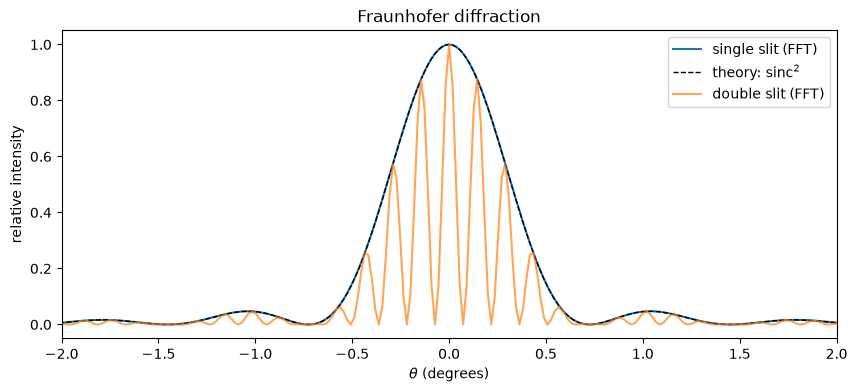

In [4]:
N = 2**14
L = 2e-3                                   # 2 mm wide computational window
x = (np.arange(N) - N//2)*L/N
lam = 633e-9                               # HeNe laser
a, d = 50e-6, 250e-6                       # slit width, slit separation

single = (np.abs(x) < a/2).astype(float)
double = ((np.abs(x - d/2) < a/2) | (np.abs(x + d/2) < a/2)).astype(float)

def far_field(aperture):
    U = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(aperture)))
    k = np.fft.fftshift(np.fft.fftfreq(N, d=L/N))*2*np.pi
    return np.arcsin(np.clip(k*lam/(2*np.pi), -1, 1)), np.abs(U)**2

theta, I1 = far_field(single)
_, I2 = far_field(double)
beta = np.pi*a*np.sin(theta)/lam

plt.figure(figsize=(10, 4))
plt.plot(np.degrees(theta), I1/I1.max(), label='single slit (FFT)')
plt.plot(np.degrees(theta), np.sinc(beta/np.pi)**2, 'k--', lw=1, label=r'theory: sinc$^2$')
plt.plot(np.degrees(theta), I2/I2.max(), alpha=0.7, label='double slit (FFT)')
plt.xlim(-2, 2); plt.xlabel(r'$\theta$ (degrees)'); plt.ylabel('relative intensity'); plt.legend()
plt.title('Fraunhofer diffraction'); plt.show()

**2D:** a circular aperture (a telescope mirror) gives the **Airy pattern**, $I(\theta)\propto\left[\frac{2J_1(ka\sin\theta)}{ka\sin\theta}\right]^2$, whose first dark ring at $\sin\theta = 1.22\lambda/D$ sets the resolution limit of every telescope and microscope. The James Webb Space Telescope's mirror is made of 18 hexagons, which is why its star images have six big spikes (plus two faint ones from the support struts). Our pixelated toy mirror is crude, but its far-field pattern already shows the six-fold symmetry of the hexagons, a lattice of peaks from the regular segment spacing, and a horizontal streak caused by the single vertical strut (diffraction spreads light *perpendicular* to a thin edge).

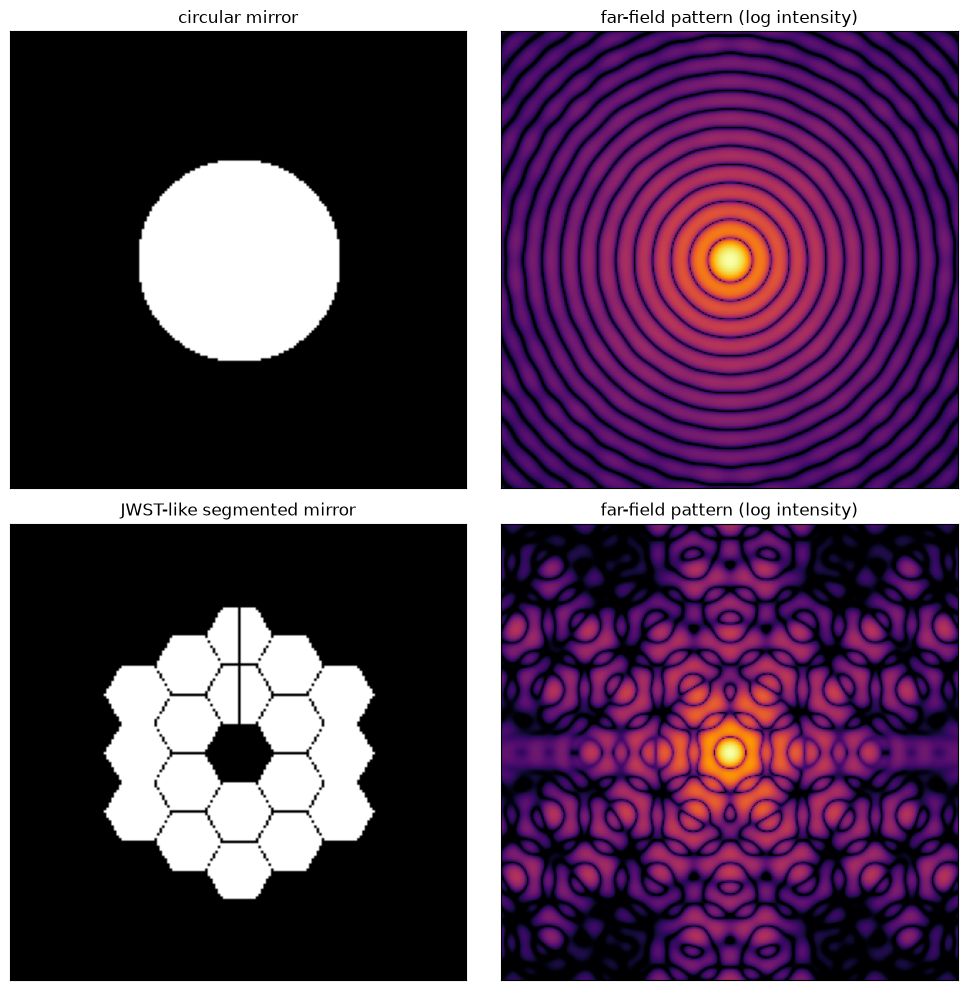

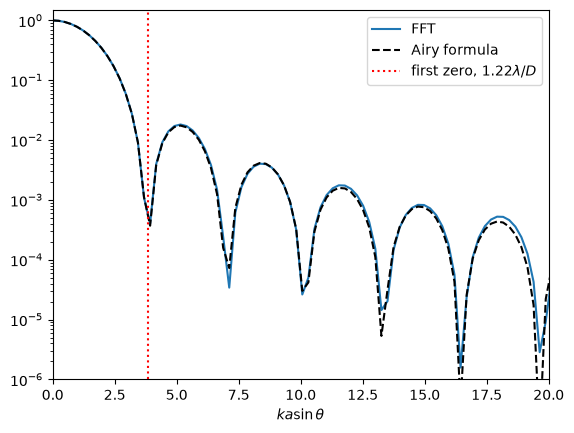

In [5]:
N = 1024
X, Y = np.meshgrid(np.arange(N) - N//2, np.arange(N) - N//2)
R = 40                                                   # aperture radius in pixels

circle = (X**2 + Y**2 < R**2).astype(float)

def hexagon(cx, cy, r):
    x, y = np.abs(X - cx), np.abs(Y - cy)
    return (y < np.sqrt(3)/2*r) & (np.sqrt(3)*x + y < np.sqrt(3)*r)

# a JWST-like mirror: 18 hexagons in two rings around a missing centre segment
seg = 13
centres = []
for q in range(-2, 3):
    for r_ in range(-2, 3):
        s = -q - r_
        if 0 < max(abs(q), abs(r_), abs(s)) <= 2:
            centres.append((1.5*seg*q*1.03, np.sqrt(3)*seg*(r_ + q/2)*1.03))
jwst = np.zeros((N, N))
for cx, cy in centres:
    jwst += hexagon(cx, cy, seg)
jwst = np.clip(jwst, 0, 1)
jwst[np.abs(X) < 1] *= (Y[np.abs(X) < 1] > 0)            # a thin vertical strut (half length)

def psf(ap):
    I = np.abs(np.fft.fftshift(np.fft.fft2(ap)))**2
    return I/I.max()

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
zoom = slice(N//2 - 160, N//2 + 160)
for row, (ap, name) in enumerate([(circle, 'circular mirror'), (jwst, 'JWST-like segmented mirror')]):
    axes[row, 0].imshow(ap[N//2-90:N//2+90, N//2-90:N//2+90], cmap='gray'); axes[row, 0].set_title(name)
    axes[row, 1].imshow(np.log10(psf(ap)[zoom, zoom] + 1e-7), cmap='inferno', vmin=-6)
    axes[row, 1].set_title('far-field pattern (log intensity)')
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

# radial cut of the circular aperture against the Airy formula
I = psf(circle)[N//2, N//2:]
q = np.arange(len(I))*2*np.pi/N*R                        # k a sin(theta) in pixel units
airy = np.ones_like(q); airy[1:] = (2*j1(q[1:])/q[1:])**2
plt.semilogy(q, I, label='FFT'); plt.semilogy(q, airy, 'k--', label='Airy formula')
plt.axvline(3.8317, color='r', ls=':', label='first zero, 1.22$\\lambda/D$')
plt.xlim(0, 20); plt.ylim(1e-6, 1.5); plt.xlabel(r'$ka\sin\theta$'); plt.legend(); plt.show()

# A3.3 Fresnel diffraction and the Cornu spiral <a class="anchor" id="fresnel"></a>
Close to the aperture the Fraunhofer approximation fails and we need the Fresnel integrals

$$C(w) = \int_0^w\cos\left(\frac{\pi t^2}{2}\right)dt, \qquad S(w) = \int_0^w\sin\left(\frac{\pi t^2}{2}\right)dt.$$

These oscillate faster and faster as $t$ grows - a nice test for quadrature. Plotting $S$ against $C$ gives the elegant **Cornu (Euler) spiral**. For light passing a **straight edge**, the intensity at a point a scaled distance $w$ into the illuminated region is

$$\frac{I}{I_0} = \frac12\left[\left(C(w)+\tfrac12\right)^2 + \left(S(w)+\tfrac12\right)^2\right],$$

i.e. half the squared distance on the spiral from the point $(-\frac12,-\frac12)$ to the point at parameter $w$.

max error vs scipy.special.fresnel: 8.412531782298061e-10


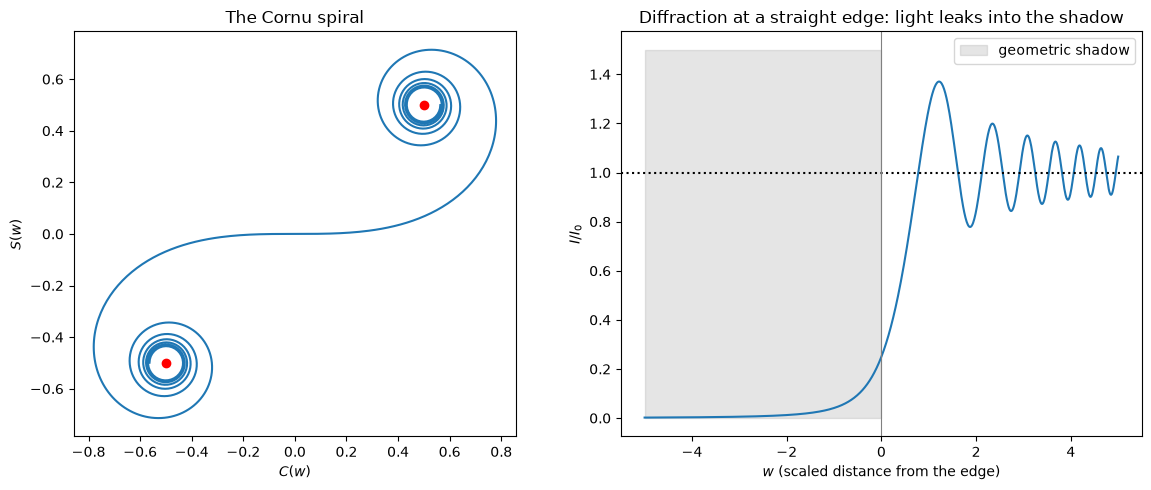

brightest fringe: I/I0 = 1.370 (theory 1.37), intensity at the edge = 0.250 (theory 0.25)


In [6]:
def fresnel_CS(w, n=2000):
    """Fresnel integrals by composite Simpson's rule (n must be even)."""
    t = np.linspace(0, w, n + 1)
    hh = w/n
    simpson = lambda y: hh/3*(y[0] + 4*y[1:-1:2].sum() + 2*y[2:-1:2].sum() + y[-1])
    return simpson(np.cos(np.pi*t**2/2)), simpson(np.sin(np.pi*t**2/2))

ws = np.linspace(-5, 5, 801)
CS = np.array([fresnel_CS(w) for w in ws])
S_ref, C_ref = fresnel(ws)                          # scipy returns (S, C)
print('max error vs scipy.special.fresnel:', np.max(np.abs(CS - np.column_stack([C_ref, S_ref]))))

I_edge = 0.5*((CS[:, 0] + 0.5)**2 + (CS[:, 1] + 0.5)**2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(CS[:, 0], CS[:, 1]); ax1.plot([-0.5, 0.5], [-0.5, 0.5], 'ro')
ax1.set_aspect('equal'); ax1.set_xlabel('$C(w)$'); ax1.set_ylabel('$S(w)$'); ax1.set_title('The Cornu spiral')
ax2.plot(ws, I_edge); ax2.axhline(1, color='k', ls=':'); ax2.axvline(0, color='grey', lw=0.8)
ax2.fill_betweenx([0, 1.5], -5, 0, color='grey', alpha=0.2, label='geometric shadow')
ax2.set_xlabel('$w$ (scaled distance from the edge)'); ax2.set_ylabel('$I/I_0$'); ax2.legend()
ax2.set_title('Diffraction at a straight edge: light leaks into the shadow')
plt.tight_layout(); plt.show()
print(f'brightest fringe: I/I0 = {I_edge.max():.3f} (theory 1.37), intensity at the edge = {I_edge[400]:.3f} (theory 0.25)')

# A3.4 Thin films and Bragg mirrors: the transfer-matrix method <a class="anchor" id="tmm"></a>
Why are soap bubbles coloured, how do anti-reflection coatings work, and how can a stack of transparent layers reflect 99.99% of light (the mirrors in laser cavities and LIGO)? All are explained by interference between reflections from many interfaces.

The **transfer-matrix method** handles any number of layers. At normal incidence, each layer $j$ (refractive index $n_j$, thickness $d_j$, phase thickness $\delta_j = 2\pi n_j d_j/\lambda$) is represented by a $2\times2$ characteristic matrix

$$M_j = \begin{pmatrix}\cos\delta_j & \frac{i}{n_j}\sin\delta_j\\ i n_j\sin\delta_j & \cos\delta_j\end{pmatrix},$$

and the whole stack is just the **matrix product** $M = M_1M_2\cdots M_N$. With incident medium $n_0$ and substrate $n_s$,

$$r = \frac{n_0 M_{11} + n_0n_sM_{12} - M_{21} - n_sM_{22}}{n_0 M_{11} + n_0n_sM_{12} + M_{21} + n_sM_{22}},\qquad R=|r|^2.$$

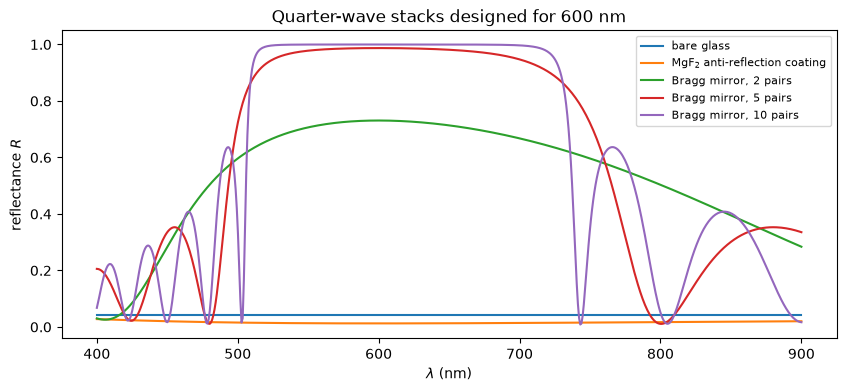

R at 600 nm: bare glass 0.0426, AR coated 0.0126, 10-pair mirror 0.999937


In [7]:
def reflectance(n_layers, d_layers, lam, n0=1.0, ns=1.52):
    R = np.zeros_like(lam)
    for k, l in enumerate(lam):
        M = np.eye(2, dtype=complex)
        for n, d in zip(n_layers, d_layers):
            delta = 2*np.pi*n*d/l
            M = M @ np.array([[np.cos(delta), 1j*np.sin(delta)/n], [1j*n*np.sin(delta), np.cos(delta)]])
        num = n0*M[0, 0] + n0*ns*M[0, 1] - M[1, 0] - ns*M[1, 1]
        den = n0*M[0, 0] + n0*ns*M[0, 1] + M[1, 0] + ns*M[1, 1]
        R[k] = abs(num/den)**2
    return R

lam = np.linspace(400e-9, 900e-9, 600)
lam0 = 600e-9
nH, nL = 2.35, 1.38                                   # TiO2 and MgF2

R_glass = reflectance([], [], lam)
R_ar = reflectance([nL], [lam0/(4*nL)], lam)          # quarter-wave anti-reflection coating
plt.figure(figsize=(10, 4))
plt.plot(lam*1e9, R_glass, label='bare glass')
plt.plot(lam*1e9, R_ar, label='MgF$_2$ anti-reflection coating')
for pairs in [2, 5, 10]:
    ns_, ds_ = [nH, nL]*pairs, [lam0/(4*nH), lam0/(4*nL)]*pairs
    plt.plot(lam*1e9, reflectance(ns_, ds_, lam), label=f'Bragg mirror, {pairs} pairs')
plt.xlabel(r'$\lambda$ (nm)'); plt.ylabel('reflectance $R$'); plt.legend(fontsize=8)
plt.title('Quarter-wave stacks designed for 600 nm'); plt.show()
print(f'R at 600 nm: bare glass {reflectance([], [], [lam0])[0]:.4f}, '
      f'AR coated {reflectance([nL], [lam0/(4*nL)], [lam0])[0]:.4f}, '
      f'10-pair mirror {reflectance([nH, nL]*10, [lam0/(4*nH), lam0/(4*nL)]*10, [lam0])[0]:.6f}')

# A3.5 Bending light: ray tracing through a graded-index medium <a class="anchor" id="rays"></a>
In a medium whose refractive index $n(\mathbf r)$ varies smoothly, light rays curve. Fermat's principle leads to the **ray equation**

$$\frac{d}{ds}\left(n\frac{d\mathbf r}{ds}\right) = \nabla n,$$

where $s$ is arc length. Introducing the "optical momentum" $\mathbf p = n\,d\mathbf r/ds$ gives a first-order system ready for `solve_ivp`:

$$\frac{d\mathbf r}{ds} = \frac{\mathbf p}{n}, \qquad \frac{d\mathbf p}{ds} = \nabla n.$$

**Graded-index optical fibre.** With $n(y)=n_0\sqrt{1-\alpha^2y^2}$ (a parabolic profile), rays oscillate sinusoidally about the axis and - to a good approximation - all rays take the same time to travel along the fibre, which reduces pulse spreading.

**A desert mirage.** Hot air near the ground has a *lower* refractive index, so rays from the sky curve **upward** and reach your eye from below - you see the sky "reflected" on the road.

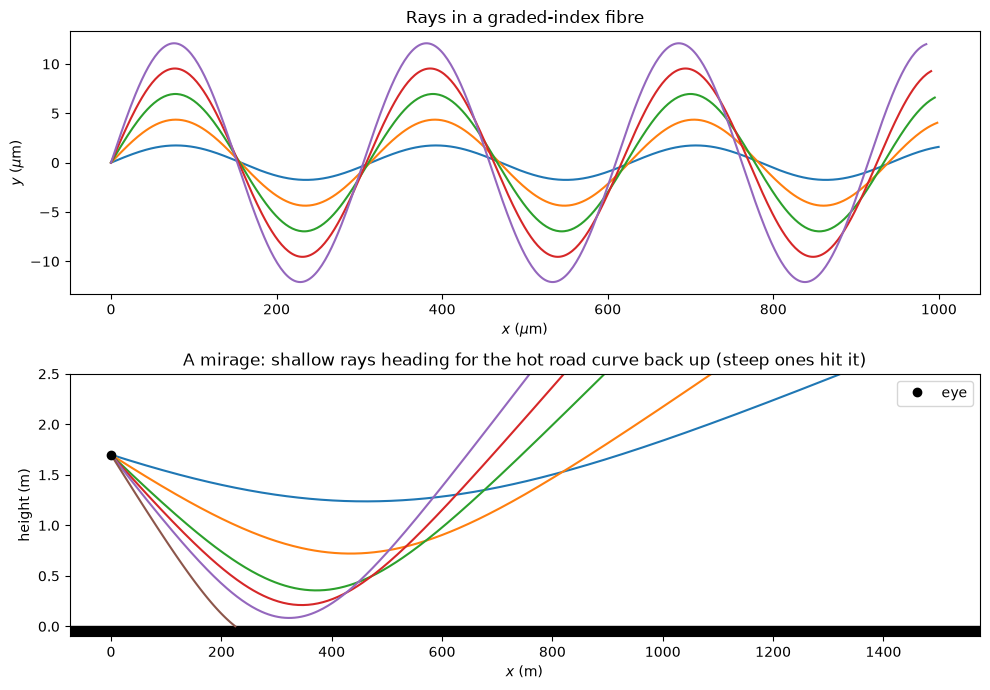

In [8]:
def trace(n, grad_n, r0, angle, s_max):
    p0 = n(*r0)*np.array([np.cos(angle), np.sin(angle)])
    def rhs(s, y):
        x, yy, px, py = y
        nn = n(x, yy)
        gx, gy = grad_n(x, yy)
        return [px/nn, py/nn, gx, gy]
    return solve_ivp(rhs, (0, s_max), [*r0, *p0], max_step=s_max/500, rtol=1e-9)

# Graded-index fibre (lengths in micrometres)
n0, alpha = 1.5, 0.02
n_fib = lambda x, y: n0*np.sqrt(1 - alpha**2*y**2)
grad_fib = lambda x, y: (0.0, -n0*alpha**2*y/np.sqrt(1 - alpha**2*y**2))

# Mirage: hot road, n decreases towards the ground (lengths in metres, height y >= 0)
dn = 3e-5                                              # ~30 K hotter at the road surface (dn/dT ~ -1e-6 per K)
n_air = lambda x, y: 1.00029 - dn*np.exp(-y/0.5)      # index is lowest at road level
grad_air = lambda x, y: (0.0, dn/0.5*np.exp(-y/0.5))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))
for ang in np.radians([2, 5, 8, 11, 14]):
    s = trace(n_fib, grad_fib, (0, 0), ang, 1000)
    ax1.plot(s.y[0], s.y[1])
ax1.set_xlabel(r'$x$ ($\mu$m)'); ax1.set_ylabel(r'$y$ ($\mu$m)'); ax1.set_title('Rays in a graded-index fibre')

for ang in np.radians(-np.array([0.1, 0.2, 0.3, 0.35, 0.4, 0.5])):
    s = trace(n_air, grad_air, (0, 1.7), ang, 1500)
    below = np.where(s.y[1] < 0)[0]
    end = below[0] if len(below) else len(s.t)       # stop the ray where it hits the road
    ax2.plot(s.y[0][:end], s.y[1][:end])
ax2.axhspan(-0.1, 0, color='k'); ax2.plot(0, 1.7, 'ko', label='eye')
ax2.set_ylim(-0.1, 2.5); ax2.set_xlabel('$x$ (m)'); ax2.set_ylabel('height (m)'); ax2.legend()
ax2.set_title('A mirage: shallow rays heading for the hot road curve back up (steep ones hit it)')
plt.tight_layout(); plt.show()

# Projects <a class="anchor" id="projects"></a>

1. **A diffraction grating.** Use the 1D FFT to compute the far-field pattern of a grating with $N=5, 10, 50$ slits. Measure how the width of the principal maxima scales with $N$, and relate it to the resolving power $\lambda/\Delta\lambda = mN$.
2. **Fresnel propagation.** Use the *angular spectrum method* - FFT the field, multiply by $e^{ik_z z}$ with $k_z=\sqrt{k^2-k_x^2-k_y^2}$, inverse FFT - to propagate light from a square aperture through the near field into the far field. Find the "Talbot effect" for a periodic grating.
3. **Soap bubble colours.** Use the transfer-matrix code to compute the reflectance spectrum of a soap film ($n=1.33$) of thickness 0-1000 nm. Convert each spectrum to an approximate RGB colour (weight by simple Gaussian sensitivity curves) and plot the colour against thickness.
4. **Looming and the Fata Morgana.** Model a temperature *inversion* over cold sea (index *decreasing* with height) and show that distant ships can appear stretched or floating above the horizon.

In [9]:
# Start working here